---
title: "ERCOT Ancillary Analysis"
format:
  html:
    echo: false
---

In [5]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

In [6]:

ercot_mcpc = pd.read_csv("../data/ercot_mcpc_comparison.csv")
ercot_mcpc["interval_start_local"] = pd.to_datetime(ercot_mcpc["interval_start_local"])

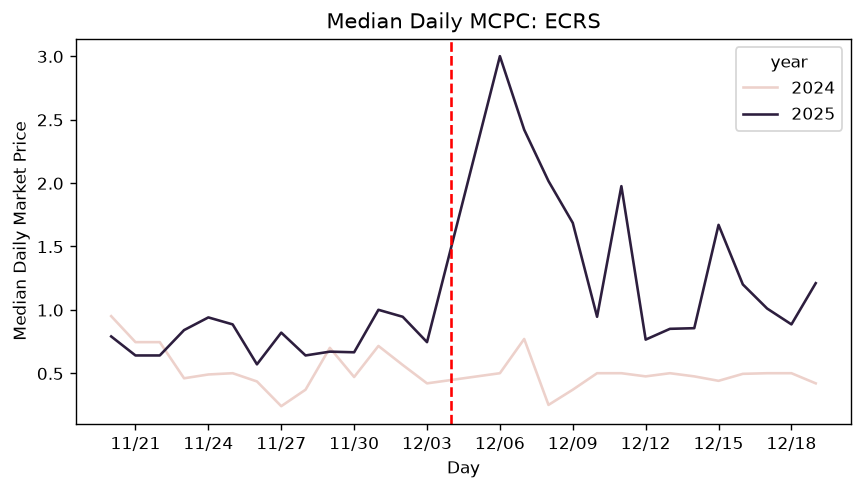

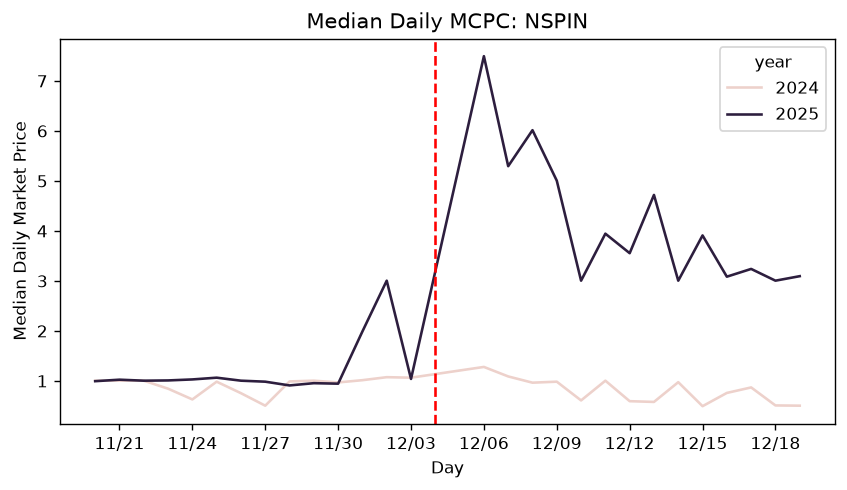

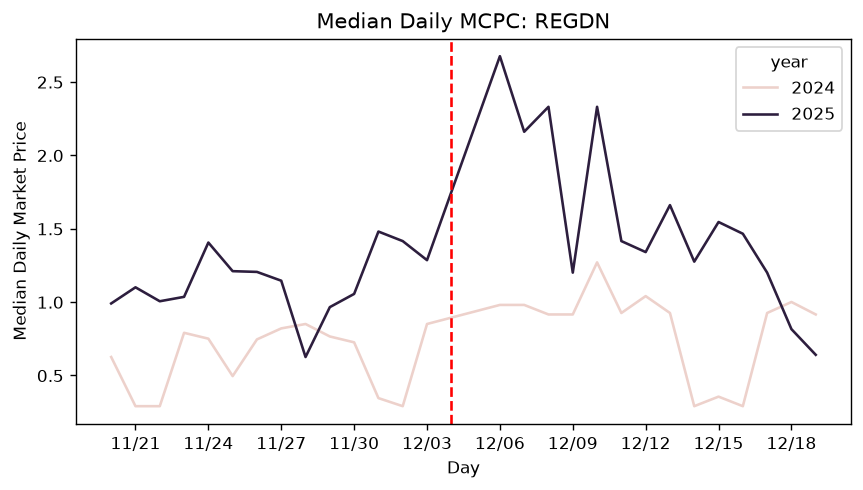

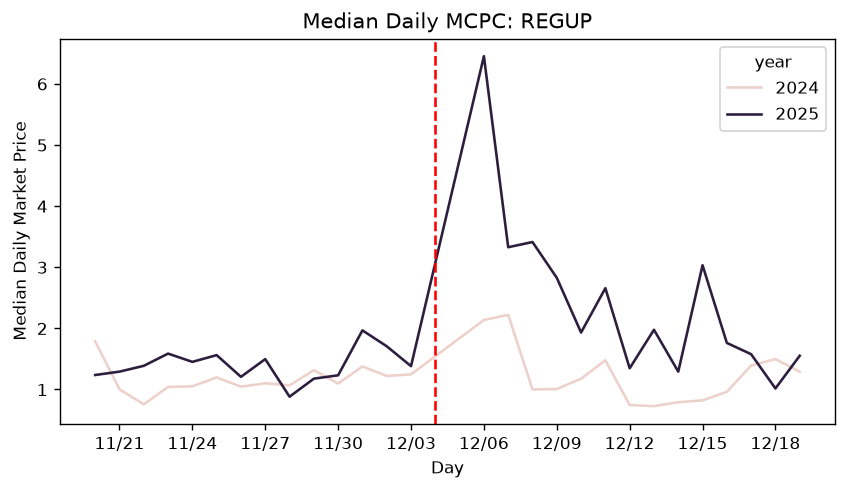

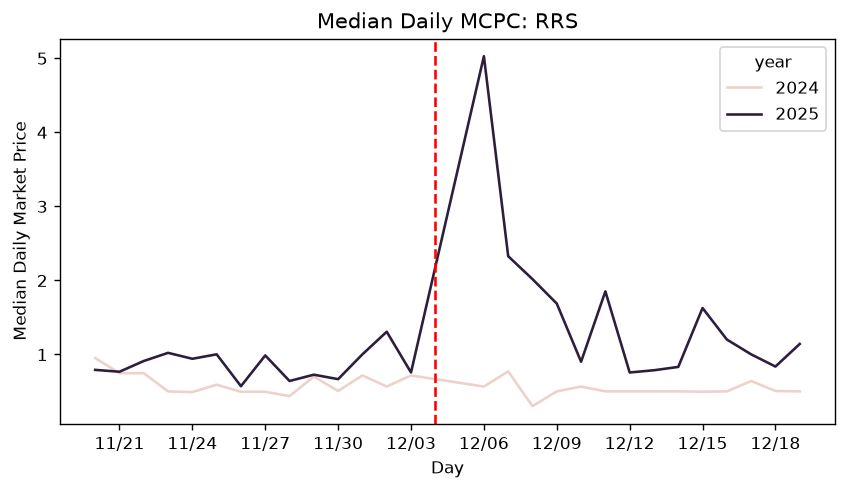

In [7]:
as_types = ercot_mcpc["as_type"].unique()

for as_type in as_types:
    plot_df = (
        ercot_mcpc.query("as_type == @as_type")
        .assign(date=lambda x: x["interval_start_local"].dt.strftime('%m/%d'))
        .groupby(["date", "year"], as_index=False)
        .agg(median_daily=("mcpc", "median"))
    )
   
    plot_df["date"] = pd.to_datetime(plot_df["date"], format="%m/%d")

    fig, ax = plt.subplots(figsize=(8, 4))
    sns.lineplot(data=plot_df, x="date",
     y="median_daily",
      hue="year",
       ax=ax)

    ax.axvline(x=pd.to_datetime("12/04",
     format="%m/%d"),
      color="red",
       linestyle="--")
    ax.set_title(f"Median Daily MCPC: {as_type}")
    ax.xaxis.set_major_locator(mdates.DayLocator(interval=3))
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%m/%d"))
    ax.set_ylabel("Median Daily Market Price")
    ax.set_xlabel("Day")
    

    plt.show()
     
